# Case study: a CO₂ VSA under plant constraints

This notebook walks through the case study of the [documentation](https://samaffleck.github.io/skarstrom/case-study-vsa/): the CO₂/N₂ VSA of Estupiñan Perez et al. (2019), run by devices (a blower, valves, one vacuum pump) on a three-bed schedule, and re-optimised under the constraints a real plant must meet.

It uses the two base decks shipped with the package, `Perez2019_CaseStudy_Base` (four-step cycle) and `Perez2019_CaseStudy_Base_LPP` (light-product pressurisation), and the results of the long optimisation committed in `examples/case_study_results/`.

1. Load the decks and read their constraint parameters.
2. Run the four-step base case to cyclic steady state.
3. Read the operating-limit report and the KPIs, and check them against the constraints.
4. See what the ramped opening of the pressurisation valve does.
5. Run a tiny optimisation.
6. Plot the three purity–recovery fronts: the paper's, the unconstrained reproduction and the constrained one.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import skarstrom as sk
from skarstrom import optimisation as opt

plt.rcParams["figure.dpi"] = 80
CO2 = "CarbonDioxide"
print("skarstrom", sk.__version__)

skarstrom 0.8.1.dev0+gf11adaa


## 1. The base decks and their constraint parameters

Every device setting and every constraint value is a global variable, so a study or an optimiser changes it by one registry path. `valve_ramp_start` and `valve_ramp_time` set the opening ramp of the pressurisation valve: it opens from that share of its C<sub>v</sub> to fully open over that time from the start of the step.

In [2]:
base = sk.examples.Perez2019_CaseStudy_Base.load()
lpp = sk.examples.Perez2019_CaseStudy_Base_LPP.load()
for sim in (base, lpp):
    print(sim.info.title)
    print("  steps:", sim.steps.names, f"cycle {sim.cycle.total_time:.1f} s")
names = ["n_beds", "t_feed", "feed_velocity", "vacuum_pump_power", "blowdown_share", "cv_vent",
         "valve_ramp_start", "valve_ramp_time", "p_evac_floor", "purity_target", "recovery_target"]
pd.DataFrame({"four-step": [base.get(f"variable[{n}]") for n in names],
              "LPP": [lpp.get(f"variable[{n}]") for n in names]}, index=names)

Perez 2019 case study - base case
  steps: ['Feed', 'Blowdown', 'Evacuation', 'Pressurisation'] cycle 297.0 s
Perez 2019 case study - base case with LPP
  steps: ['Feed 1', 'Feed 2', 'Blowdown', 'Evacuation', 'Pressurisation', 'Idle'] cycle 433.5 s


,four-step,LPP
n_beds,3.00000,3.0000
t_feed,99.00000,144.5000
feed_velocity,0.08487,0.0328
vacuum_pump_power,10.20000,5.8500
blowdown_share,0.20500,0.2330
cv_vent,0.50000,0.5000
valve_ramp_start,0.10000,0.2000
valve_ramp_time,20.00000,8.0000
p_evac_floor,10000.00000,10000.0000
purity_target,0.95000,0.9500


## 2. Run the four-step base case

The run stops at cyclic steady state (about 50 cycles, under a minute). Check the status and the run-health warnings before reading any number.

In [3]:
result = base.run()
print(result.status, "| CSS at cycle", result.css_cycle, "| healthy:", result.healthy)
for w in result.warnings:
    print(" ", w.code, w.value, w.hint)

reached_css | CSS at cycle 48 | healthy: True


## 3. Operating limits and KPIs

`sim.operating_limits()` gives the pressure and fluidisation extremes of each step of the last cycle. The case study's practical constraints are read from it: the approach to fluidisation (≤ 1 on every packed face) and the lowest pressure in blowdown and evacuation (≥ `p_evac_floor`).

In [4]:
report = base.operating_limits()
limits = pd.DataFrame([{"step": s.step_name, "min pressure [kPa]": s.min_pressure / 1e3,
                        "max pressure [kPa]": s.max_pressure / 1e3,
                        "max approach to fluidisation": s.max_approach_to_fluidisation} for s in report.steps])
print([w.message for w in report.warnings])
limits.round(3)

[]


,step,min pressure [kPa],max pressure [kPa],max approach to fluidisation
0,Feed,99.997,101.009,0.159
1,Blowdown,6.679,100.675,0.979
2,Evacuation,3.919,7.612,0.979
3,Pressurisation,3.919,99.997,0.945


In [5]:
k = next(k for k in base.kpis(cycle=-1) if k.component == CO2)
floor = base.get("variable[p_evac_floor]")
vacuum = limits[limits["step"].isin(["Blowdown", "Evacuation"])]["min pressure [kPa]"].min() * 1e3
checks = pd.DataFrame([
    ("CO2 purity", k.purity, base.get("variable[purity_target]"), k.purity >= base.get("variable[purity_target]")),
    ("CO2 recovery", k.recovery, base.get("variable[recovery_target]"), k.recovery >= base.get("variable[recovery_target]")),
    ("approach to fluidisation", limits["max approach to fluidisation"].max(), 1.0,
     limits["max approach to fluidisation"].max() <= 1.0),
    ("lowest vacuum pressure [Pa]", vacuum, floor, vacuum >= floor),
], columns=["constraint", "value", "bound", "met"])
print(f"specific energy {k.electrical_energy / 3600:.0f} kWh/t CO2, productivity {k.productivity_mass * 3.6e6:.1f} kg/(t h)")
checks

specific energy 206 kWh/t CO2, productivity 90.9 kg/(t h)


,constraint,value,bound,met
0,CO2 purity,0.995724,0.95,True
1,CO2 recovery,0.594882,0.90,False
2,approach to fluidisation,0.979173,1.00,True
3,lowest vacuum pressure [Pa],3918.649677,10000.00,False


The base point meets the fluidisation constraint and the purity target. It misses the recovery target, and its evacuation goes far below the 10 kPa floor, as the paper's does.

## 4. The ramped valve opening

Run the same deck with the pressurisation valve fully open from the start of the step (`valve_ramp_start` = 1, `valve_ramp_time` = 0) and compare the flow through the valve and the approach to fluidisation in the pressurisation step.

reached_css True


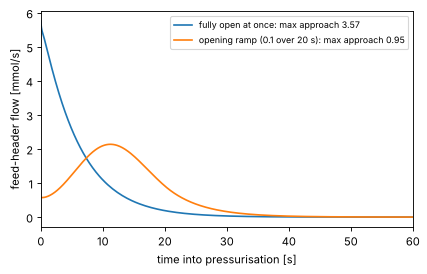

In [6]:
open_valve = sk.examples.Perez2019_CaseStudy_Base.load()
open_valve["variable[valve_ramp_start]"] = 1.0
open_valve["variable[valve_ramp_time]"] = 0.0
r_open = open_valve.run()
print(r_open.status, r_open.healthy)

i = base.steps.names.index("Pressurisation")
fig, ax = plt.subplots(figsize=(6, 3.5))
for sim, label in ((open_valve, "fully open at once"), (base, "opening ramp (0.1 over 20 s)")):
    f = sim.stream_series(i, "Feed header", "molar_flow_rate")
    af = next(s.max_approach_to_fluidisation for s in sim.operating_limits().steps if s.step_name == "Pressurisation")
    ax.plot(f.time - f.time[0], f.values * 1e3, label=f"{label}: max approach {af:.2f}")
ax.set_xlim(0, 60)
ax.set_xlabel("time into pressurisation [s]")
ax.set_ylabel(f"feed-header flow [mmol/s]")
ax.legend(fontsize=8)
plt.show()

Fully open, the valve passes its largest flow in the first instant, into an evacuated bed, and lifts the bed at the feed end. The ramp spreads the same gas over the first half minute; the bed still reaches 1 bar well within its 99 s step.

## 5. A tiny optimisation

`skarstrom.optimisation.optimise` searches registry paths with a surrogate model and warm starts. Here: the vacuum pump power, for the best CO₂ recovery at a purity of at least 95 %, in six runs. The full case-study search (`examples/perez_2019_case_study_optimise.py`, NSGA-II) adds the operating-limit constraints and runs thousands of candidates.

In [7]:
r = opt.optimise(base, {"variable[vacuum_pump_power]": (4.0, 14.0)},
                 objectives=[opt.maximise(CO2, "recovery")],
                 constraints=[opt.at_least(CO2, "purity", 0.95, penalty=10)],
                 evaluations=6, init_samples=3)
print("best vacuum_pump_power", r.x)
r.table()

best vacuum_pump_power {'variable[vacuum_pump_power]': 14.0}


,index,variable[vacuum_pump_power],cost,CarbonDioxide.cooling_duty,CarbonDioxide.thermal_energy,CarbonDioxide.production_rate,CarbonDioxide.energy_consumption,CarbonDioxide.productivity_volume,CarbonDioxide.productivity_mass,CarbonDioxide.recovery,CarbonDioxide.purity,status,accepted,warm,distance,cycles_run,css_reached,wall_time_s,note,message
0,0,9.000000,-0.596064,0.0,0.0,0.000093,645421.415181,0.016973,0.000025,0.596064,0.979408,reached_css,True,False,NaN,49,True,36.517633,,cyclic steady state reached at cycle 49
1,1,6.332727,0.017430,0.0,0.0,0.000080,507895.793134,0.014524,0.000022,0.514237,0.896833,reached_css,True,True,0.266727,40,True,28.734046,,cyclic steady state reached at cycle 40
2,2,11.626503,-0.600350,0.0,0.0,0.000094,848083.975892,0.017161,0.000026,0.600350,0.999999,reached_css,True,True,0.262650,38,True,28.636550,,cyclic steady state reached at cycle 38
3,3,10.332166,-0.593578,0.0,0.0,0.000093,755527.697389,0.016927,0.000025,0.593578,0.996837,reached_css,True,True,0.129434,33,True,26.125550,,cyclic steady state reached at cycle 33
4,4,13.997347,-0.625793,0.0,0.0,0.000099,988780.090790,0.017968,0.000027,0.625793,1.000000,reached_css,True,True,0.237084,37,True,27.109881,,cyclic steady state reached at cycle 37
5,5,14.000000,-0.625801,0.0,0.0,0.000099,988964.108096,0.017969,0.000027,0.625801,1.000000,reached_css,True,True,0.000265,4,True,3.003635,,cyclic steady state reached at cycle 4
6,-1,14.000000,-0.625819,0.0,0.0,0.000099,988934.773863,0.017969,0.000027,0.625819,1.000000,reached_css,True,False,NaN,50,True,36.242878,,cyclic steady state reached at cycle 50


## 6. The three fronts

The long search (`examples/perez_2019_case_study_optimise.py`, both objective sets, both decks) wrote every evaluation to a results file; `--summary` reduced it to the tables in `examples/case_study_results/`. `fronts.csv` holds, for each deck:

- **paper**: the paper's operating points (Table 3, the paper's model);
- **unconstrained**: the purity–recovery front of every converged evaluation (cyclic steady state and a healthy run only);
- **plant_limits**: the same with the practical constraints: approach to fluidisation ≤ 1, bed pressure drop ≤ 10 kPa/m, and the lowest vacuum pressure ≥ 10 kPa.

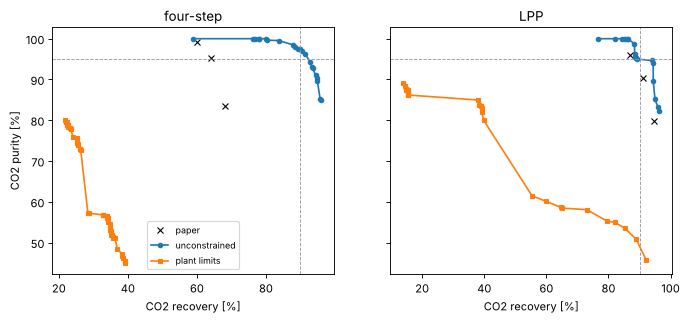

In [8]:
results = Path.cwd().parent / "case_study_results"   # this notebook is in examples/notebooks/
fronts = pd.read_csv(results / "fronts.csv")
cost = pd.read_csv(results / "constraint_cost.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
styles = {"paper": dict(marker="x", color="k", ls="none"), "unconstrained": dict(marker="o", ms=4),
          "plant_limits": dict(marker="s", ms=4)}
for ax, (deck, title) in zip(axes, (("Base", "four-step"), ("Base_LPP", "LPP"))):
    for front, style in styles.items():
        d = fronts[(fronts.deck == deck) & (fronts.front == front)].sort_values("recovery")
        ax.plot(100 * d.recovery, 100 * d.purity, label=front.replace("_", " "), **style)
    ax.axhline(95, color="0.6", lw=0.8, ls="--")
    ax.axvline(90, color="0.6", lw=0.8, ls="--")
    ax.set_title(title)
    ax.set_xlabel("CO2 recovery [%]")
axes[0].set_ylabel("CO2 purity [%]")
axes[0].legend(fontsize=8)
plt.show()

In [9]:
cost

,deck,constraints,evaluations,best_recovery_at_purity_target,best_purity_at_recovery_target
0,Base,none,1050,0.912983,0.971028
1,Base,fluidisation,801,0.841631,0.839488
2,Base,pressure_drop,1000,0.897303,0.943716
3,Base,evacuation_floor,368,NaN,NaN
4,Base,all,364,NaN,NaN
5,Base_LPP,none,836,0.892544,0.946595
6,Base_LPP,fluidisation,758,0.892544,0.946595
7,Base_LPP,pressure_drop,702,0.892544,0.946595
8,Base_LPP,evacuation_floor,272,NaN,0.458004
9,Base_LPP,all,242,NaN,0.458004


The dashed lines are the targets, 95 % purity and 90 % recovery. `constraint_cost.csv` gives what each practical constraint costs on its own: the best recovery at 95 % purity and the best purity at 90 % recovery under no constraint, each constraint alone, and all of them. See the [case-study page](https://samaffleck.github.io/skarstrom/case-study-vsa/) for the discussion: which constraint decides, and what the laboratory column cannot reach.